In [1]:
import sys
import os

# Настройка пути
sys.path.insert(0, os.path.abspath('..'))

# Импорт сторонних библиотек
import numpy as np
import matplotlib.pyplot as plt

# Импорт своих модулей
from src.linear_regression import *
from src.scalers import StandardScaler
from src.metrics import mean_squared_error, r2_score


plt.style.use('ggplot')

## Функция для визуализации

In [2]:
def create_frames():
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 9))
    axes[0][0].set_title('Линейная регрессия аналитически')
    axes[0][1].set_title('Линейная регрессия градиентным спуском')
    axes[1][0].set_title('Гребневая регрессия аналитически')
    axes[1][1].set_title('Гребневая регрессия градиентным спуском')
    return fig, axes


def plot_learning_curves(model1, model2):
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 6), sharey='row')
    models = [model1, model2]
    for i, model in enumerate(models):
        axes[0][i].plot(model.losses_, label='Train', lw=2)
        axes[0][i].plot(model.test_losses_, label='Test', lw=2, linestyle='--')
        axes[1][i].plot(model.scores_, label='Train', lw=2)
        axes[1][i].plot(model.test_scores_, label='Test', lw=2, linestyle='--')
        axes[1][i].set_yticks(np.arange(0.0, 1.2, 0.2))
    axes[0][0].set_title('Линейная регрессия')
    axes[0][1].set_title('Гребневая регрессия')
    axes[0][0].set_ylabel('MSE')
    axes[1][0].set_ylabel('R2-score')
    axes[1][0].set_xlabel('Epochs')
    axes[1][1].set_xlabel('Epochs')

    for ax in axes.flat:
        ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()


def plot_mse_r2_bars(model1, model2, X_train, y_train, X_test, y_test):
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))
    models = [model1, model2]
    for i, model in enumerate(models):
        y_pred_train = model.predict(X_train)
        y_pred_test = model.predict(X_test)
        train_mse = mean_squared_error(y_train, y_pred_train)
        test_mse = mean_squared_error(y_test, y_pred_test)
        train_r2 = r2_score(y_train, y_pred_train)
        test_r2 = r2_score(y_test, y_pred_test)
        axes[i].bar(
            x = ['Train MSE', 'Test MSE', 'Train R2', 'Test R2'],
            height=[train_mse, test_mse, train_r2, test_r2],
            edgecolor='black',
            color=['skyblue', 'red', 'skyblue', 'red']
        )
    axes[0].set_title('Метрики аналитического решения')
    axes[1].set_title('Метрики аналитического решения с L2-регуляризацией')
    plt.tight_layout()
    plt.show()



# Поиск аналитического решения

## Модель для аналитического решения

Аналитическое решение задачи линейной регрессии, являющееся решением задачи наименьших квадратов, т.к. минимизирует MSE, 
находится путем приравнивания градиента функции потерь к нулю и имеет вид:

$$
w = (X^T X)^{-1} X^T y
$$

где:
* $X$ — матрица признаков (объекты $\times$ признаки),
* $y$ — вектор целевых значений,
* $w$ — вектор искомых весов (коэффициентов),
* $X^T$ — транспонированная матрица $X$,
* $(...)^{-1}$ — операция взятия обратной матрицы.

Важно помнить, что аналитическое решение существует не всегда: если существуют линейно зависимые признаки, то обратной матрицы может не быть.
В таком случае можно либо брать псевдообратную матрицу, либо применять регуляризацию.

## Модель для аналитического решения с L2-регуляризацией

Для предотвращения переобучения и улучшения обусловленности матрицы применяется L2-регуляризация. Аналитическое решение в этом случае принимает вид:

$$
w = (X^T X + \lambda I)^{-1} X^T y
$$

где:
* $\lambda$ — коэффициент регуляризации (гиперпараметр, контролирующий силу штрафа),
* $I$ — единичная матрица соответствующего размера.

Важно, что смещение (bias), также входит в вектор w. Для его вычисления к исходному набору X добавляется фиктивный столбец из единичек.
Аналитического решения для L1-регуляризации нет

# Алгоритм полного градиентного спуска, Gradient Descent

## Линейная регрессия без регуляризации
Функция потерь (Mean Squared Error, MSE) для линейной регрессии:

$$
L(w, b) = \frac{1}{N} \sum_{i=1}^{N} (y_i - \hat{y}_i)^2
$$

где $\hat{y}_i = X_i w + b$ — предсказание модели для $i$-го объекта.

Градиенты функции потерь для обновления весов и смещения:

$$
\frac{\partial L}{\partial w} = \frac{2}{N} X^T (Xw + b - y)
$$

$$
\frac{\partial L}{\partial b} = \frac{2}{N} \sum_{i=1}^{N} (X_i w + b - y_i)
$$

## Линейная регрессия с L2-регуляризацией, Гребневная (Ridge) регрессия
Функция потерь с добавлением L2-регуляризации (штраф за большие веса):

$$
L_{ridge}(w, b) = L(w, b) + \alpha \sum_{j=1}^{d} w_j^2
$$

где $\alpha$ — коэффициент регуляризации, $d$ — количество признаков.

Градиент по весам:

$$
\frac{\partial L_{ridge}}{\partial w} = \frac{2}{N} X^T (Xw + b - y) + 2\alpha w
$$

Градиент по смещению $b$ остается без изменений, так как смещение (bias) регуляризовать не нужно:

$$
\frac{\partial L_{ridge}}{\partial b} = \frac{\partial L}{\partial b} = \frac{2}{N} \sum_{i=1}^{N} (X_i w + b - y_i)
$$

## Обновление весов

В обоих алгоритмах на каждом шаге иттерации (эпохе), по всему объёму данных вычисляется ошибка и градиент по весам и смещению.
Далее изменение весов благодаря вычитанию из весов градиента, умноженного на шаг обучения $\eta$:

$$
w := w - \eta \frac{\partial L}{\partial w}
$$

$$
b := b - \eta \frac{\partial L}{\partial b}
$$

где $\eta$ (эта) — скорость обучения (learning rate), определяющая размер шага.

## Генерация данных

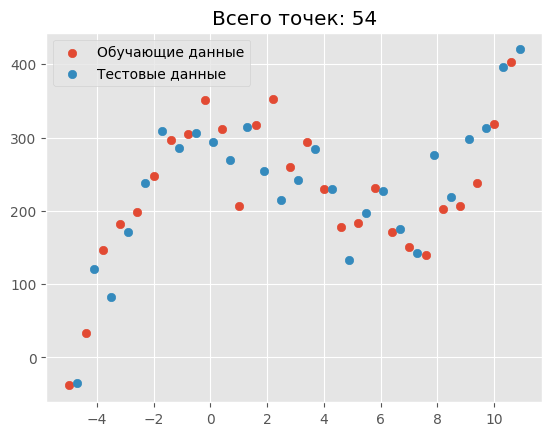

In [3]:
np.random.seed(0)
X = np.arange(-5, 11, 0.3)
y = X**3 - 10 * X**2 + 5 * X + 300 + np.random.normal(0.0, 35, size=X.shape)
plt.scatter(X[::2], y[::2], label='Обучающие данные')
plt.scatter(X[1::2], y[1::2], label='Тестовые данные')
plt.legend()
plt.title(f'Всего точек: {X.shape[0]}')
plt.show()

In [4]:
N = 17
X_N = np.array([[np.random.normal(0.0, 1, size=a.shape) + a ** n for n in range(1, N+1)] for a in X])
X_train = X_N[::2]
X_test = X_N[1::2]
y_train = y[::2]
y_test = y[1::2]

X_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)

X_train, X_test = X_scaler.transform(X_train), X_scaler.transform(X_test)
y_train, y_test = y_scaler.transform(y_train), y_scaler.transform(y_test)


# Аналитическое решение

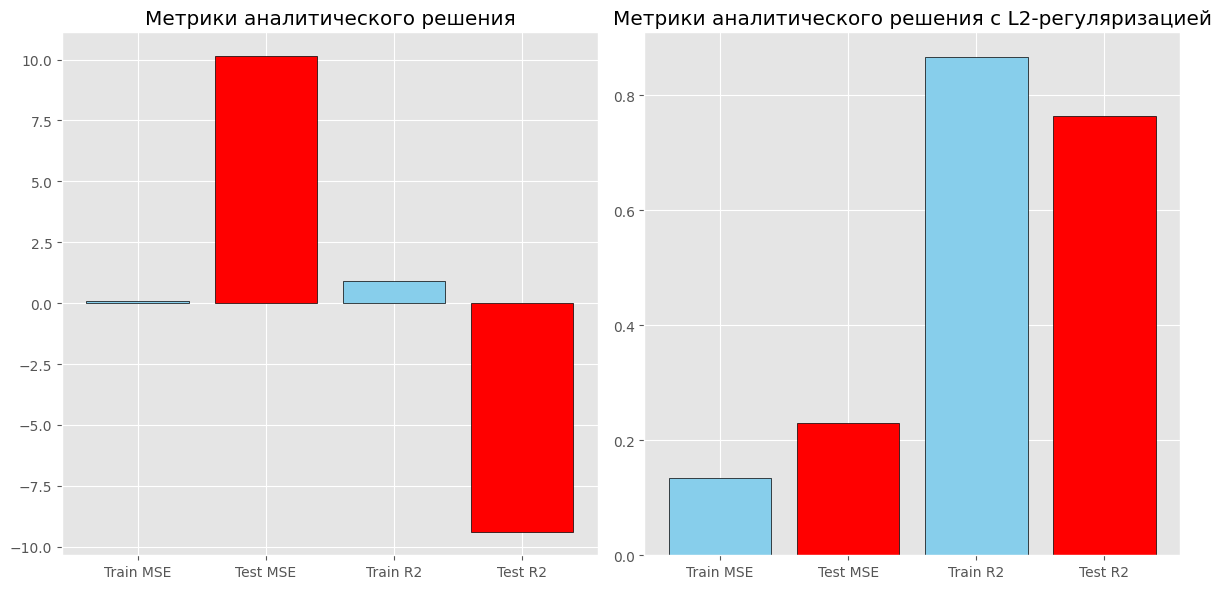

In [5]:
lr_A = LinearRegressionAnalytics(alpha=0.0).fit(X_train, y_train)
Ridge_A = LinearRegressionAnalytics(alpha=0.005).fit(X_train, y_train)
plot_mse_r2_bars(lr_A, Ridge_A, X_train, y_train, X_test, y_test)

На этих диаграммах видно, что без регуляризации модель явно переобучилась, то есть настроилась исключительно на обучающие данные. Она обучена минимизировать MSE, и действительно обучающий MSE очень низкий, но на тестовых данных ошибки колоссальные. Показатель R2 показывает, что обучающие данные описаны хорошо и метрика высокая, но с тестовыми данными предсказания абсолютно не связаны.

Модель с L2-регуляризацией более устойчива и обладает обобщающей способностью, т.к. R2 на обучении и тестировании очень близки.

Происходит так, потому что простое аналитическое решение ставит перед собой одну конкретную задачу: минимизировать ошибку на ОБУЧАЮЩЕЙ выборке. Из-за этого значения весов подстраиваются специально для попадания в глобальный минимум конкретно на обучающих данных и могут обладать худшей обобщающей способностью.

Аналитическое решение с L2-регуляризацией, помимо минимизации ошибки, решает и вторую задачу: минимизацию суммы квадратов весов. Из-за этого решение получается более устойчивым и способно к обобщению новых данных. Главная причина такого поведения будет видна ниже.

# Полный градиентный спуск

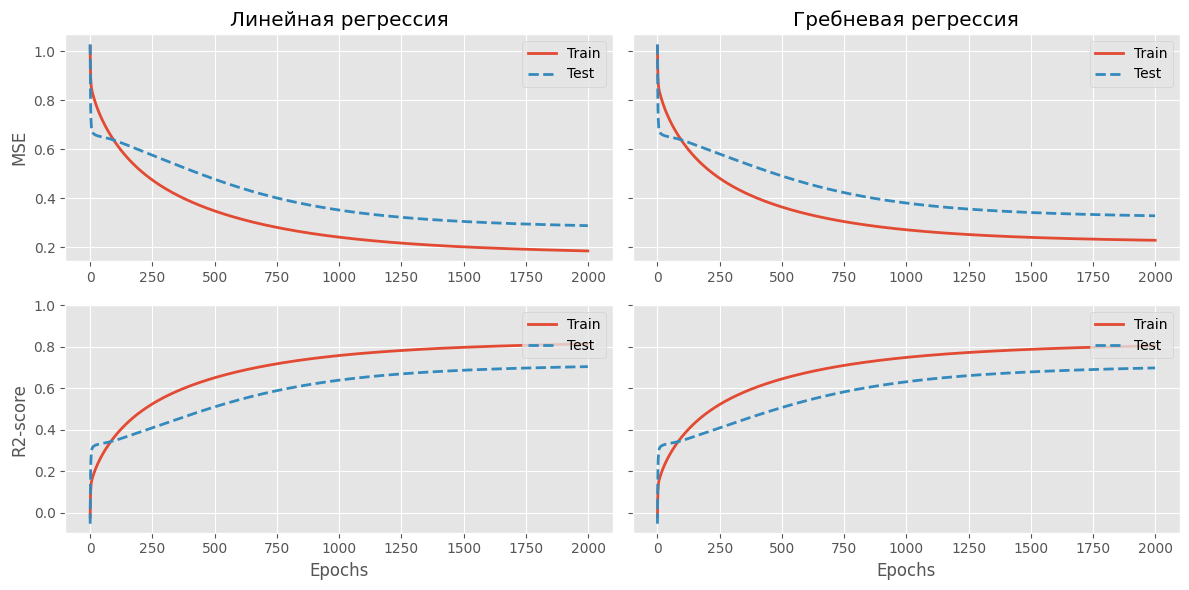

In [6]:
lr_GD = LinearRegression(eta=0.01, n_iter=2000).fit(X_train, y_train, X_test, y_test)
Ridge_GD = Ridge(eta=0.01, n_iter=2000, alpha=0.005).fit(X_train, y_train, X_test, y_test)
plot_learning_curves(lr_GD, Ridge_GD)


Здесь видно, что обычная линейная регрессия и линейная регрессия с регуляризацией, дают примерно похожие результаты. Здесь модель не дошла до глобального минимума, который отыскало аналитическое решение, и остановилась около локального минимума. Можно сказать, что регуляризация произошла за счёт ограничения числа шагов и размера самого шага обучения.

# Визуализация весов

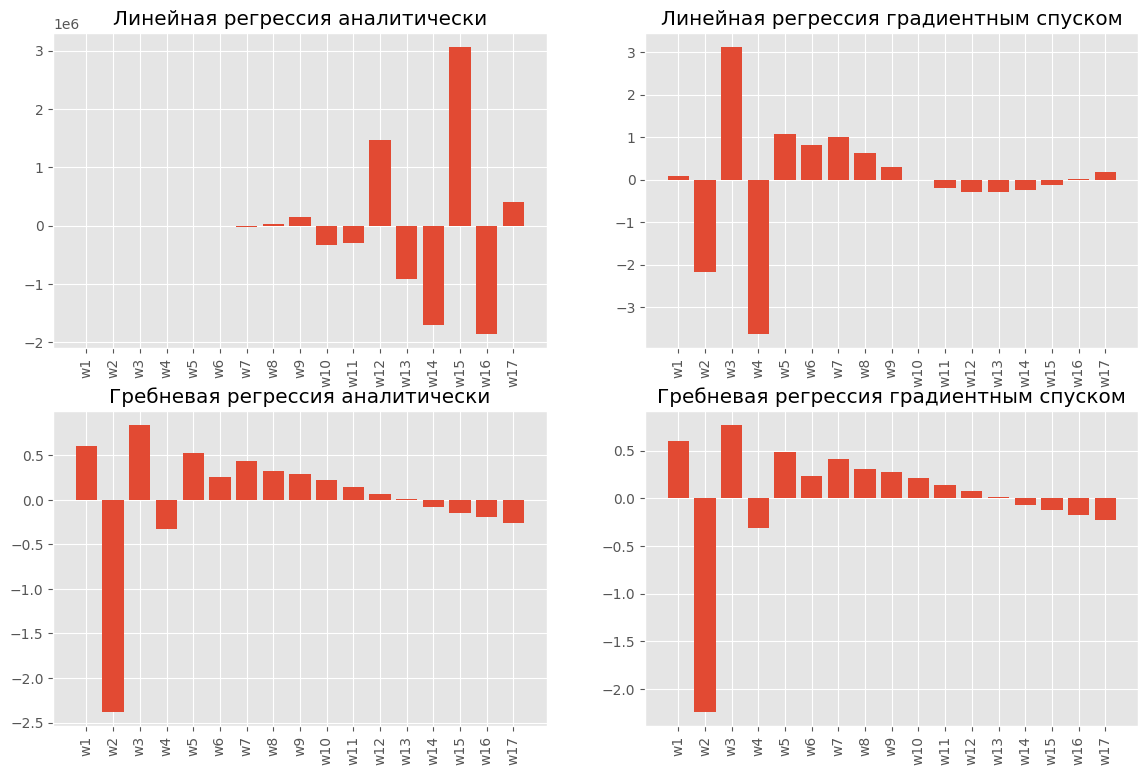

In [7]:
fig, axes = create_frames()
w_names = [f'w{i}' for i in range(1, N+1)]
axes[0][0].bar(
    x=w_names, height=lr_A.w_
)
axes[1][0].bar(
    x=w_names, height=lr_GD.w_
)
axes[0][1].bar(
    x=w_names, height=Ridge_A.w_
)
axes[1][1].bar(
    x=w_names, height=Ridge_GD.w_
)
for ax in axes.flat:
    ax.tick_params(axis='x', labelrotation=90)
plt.show()


Здесь наглядно видно, почему аналитическое решение без регуляризации переобучается: значения весов разбросаны от огромных отрицательных значений до огромных положительных таким образом, чтобы все ответы сходились именно на обучающей выборке. Когда попадается тестовое значение с небольшим различием в признаках, это небольшое различие умножается на гигантский вес и как следствие ответ далёк от ожидаемого.
Также видно, что пусть метрики у моделей с регуляризацией и без неё достаточно близки, значения весов всё равно отличны. Связано это с тем, что в L2-регуляризации также дополнительно решается задача по минимизации суммы квадратов весов. На диаграммах видно, что при использовании L2-регуляризации значения весов действительно ближе к нулю, чем в обычной линейной регрессии.

# Визуализация предсказаний

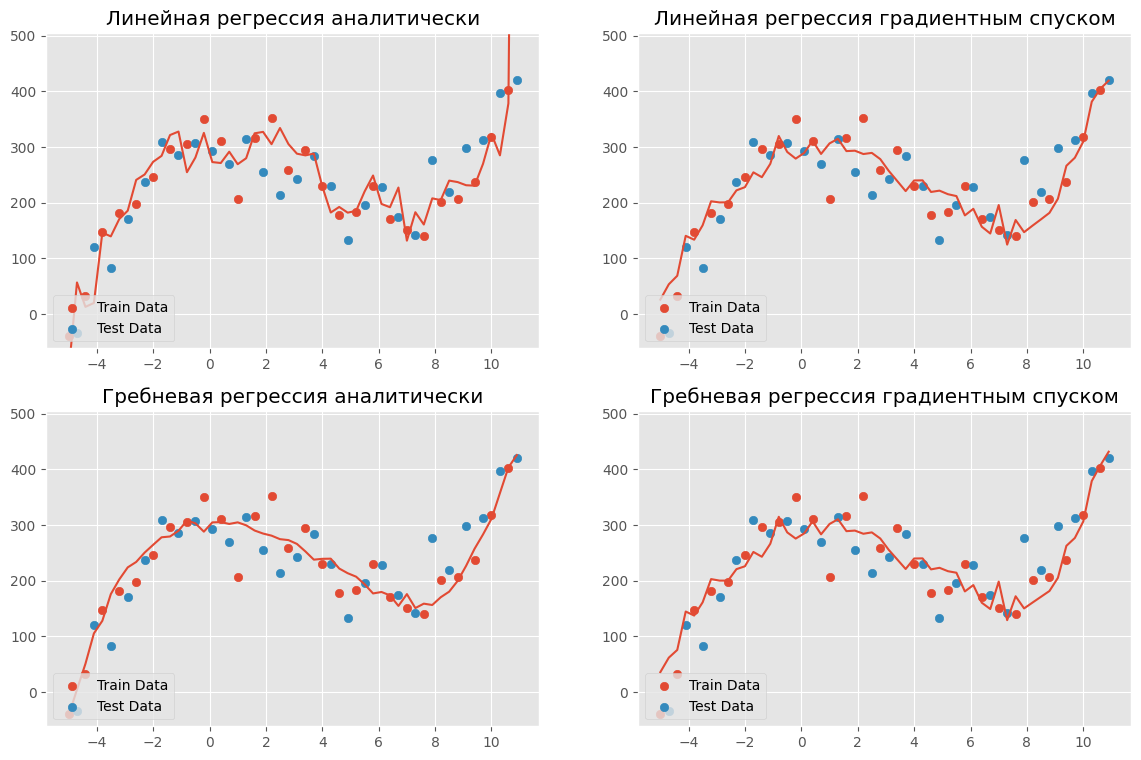

In [8]:
fig, axes = create_frames()
for ax in axes.flat:
    ax.scatter(X[::2], y[::2], label='Train Data')
    ax.scatter(X[1::2], y[1::2], label='Test Data')
    ax.legend(loc='lower left')
    ax.set_ylim(top=max(y) + 0.2 * max(y))
X_N_scaled = X_scaler.transform(X_N)
axes[0][0].plot(X, y_scaler.inverse_transform(lr_A.predict(X_N_scaled)))
axes[0][1].plot(X, y_scaler.inverse_transform(lr_GD.predict(X_N_scaled)))
axes[1][0].plot(X, y_scaler.inverse_transform(Ridge_A.predict(X_N_scaled)))
axes[1][1].plot(X, y_scaler.inverse_transform(Ridge_GD.predict(X_N_scaled)))
plt.show()

На этих графиках видно, как каждая из моделей описывает исходные данные. Аналитическое решение, как мы и обсудили ранее, из-за слишком больших весов крайне нестабильно и виден большой разброс в предсказаниях при небольшом изменении признака. Аналитическое решение старается пройти как можно ближе к каждой из точек в обучающих данных, из-за чего график настолько ломаный. Остальные модели не имеют таких резких "холмов" и способны описывать как обучающие, так и тестовые данные.

# Вывод: 
### в этом примере были приведены формулы, по которым работает линейная регрессия, а также гребневая регрессия и рассмотрены два подхода: аналитический и полный градиентный спуск. Мы рассмотрели, почему аналитическое решение сильно переобучается и увидели это в метриках, в показателях весов и визуализации предсказаний на исходных данных. Также мы увидели, что решение градиентным спуском вовсе не обязано стремиться к тому же минимуму, что и аналитическое решение. В нашем случае аналитическое решение нашло глобальный минимум по функции потерь конкретно по обучающей выборке, из-за чего оказалось неспособно адекватно описывать тестовые данные. Решение градиентным спуском сошлось в локальном минимуме с относительно маленькими показателями весов, сохранив обобшающую способность. L2-регуляризация дала схожие результаты при обеих реализациях, так как решает сразу две задачи: минимизацию ошибки на обучающей выборке и минимизацию суммы квадратов весов, из-за чего веса не могут изменяться также свободно, как без регуляризации.